# O+O with ISR: what the hard-momentum subtraction does

Two campaigns of [`run_compare.sh`](run_compare.sh) that differ in one setting only,
3dMCGlauber's `Subtract_hard_momentum`:

| campaign | folder | the hard partons' momentum |
|---|---|---|
| **subtracted** (the default) | `sub/` | taken from the colliding nucleons: the strings get Npart √s/2 minus what the hard pair took (subtracted energy + the pair's remnants) |
| **not subtracted** (reference) | `nosub/` | not taken: the strings keep the full Npart √s/2, and the jet hadrons carry the hard pair's energy as well, so that energy is counted twice |

Both: O+O 200 GeV in **0–80% centrality** by geometry (b < 5.6 fm, the 80th percentile of
b of inelastic collisions with these 3dMCGlauber settings; b drawn uniformly in b² and
redrawn until Npart ≥ 2), pTHat windows 10–20, 20–30, 30–40 GeV,
both outgoing hard partons at |y| < 0.6 (before the ISR), 40 jobs × 75 events = 1000
events per window, bulk hadrons with 10 iSS oversamples per event, jet hadrons from
iColored. The same seeds, so the same Pythia hard events, event by event; 3dMCGlauber's
geometry differs from the second event of a job on (the subtraction draws from its random
stream), so the two are compared as **ensembles**.

**Event weight.** The hard scattering sits at one binary collision drawn uniformly, one per
event whatever the geometry, while the hard-process rate grows with Ncoll. With
`WEIGHT = "ncoll"` (default) every average is weighted with Ncoll, i.e. hard events in
minimum-bias collisions; `"none"` gives every event the same weight.

1. The event samples and the energy bookkeeping
2. **The centrality bias**: multiplicity vs Npart, centrality classes from the multiplicity
3. The bulk: dN/dη, dE/dη, pT spectrum
4. The jet hadrons: dN/dη, dE/dη, pT spectrum
5. The energy as a function of the parton pT (pTHat)
6. Summary table per pTHat window

In [1]:
%matplotlib inline
import glob
import json
import os
import h5py
try:  # registers Blosc, the default compression of the production files
    import hdf5plugin  # noqa: F401
except ImportError:
    print("note: pip install hdf5plugin -- needed for Blosc-compressed files")
import numpy as np
import matplotlib.pyplot as plt

# the folder with sub/ and nosub/ (default: next to this notebook)
DIR = os.environ.get("HSC_DIR", ".")
CAMPAIGNS = {"sub": "subtracted", "nosub": "not subtracted"}
SQRTS = 200.0                   # GeV per nucleon pair: E_beam = Npart sqrt(s)/2
WEIGHT = "ncoll"                # event weight: "ncoll" (hard-process rate) or "none"
MID = 0.5                       # |eta| < MID: midrapidity yields
ETA_PT = 1.0                    # |eta| < ETA_PT for the pT spectra
PT_VAR = "pthat"                # x of section 5: "pthat" (the hard partons' pT before ISR)
                                # or "parton_pt_lead" (the harder of the two after ISR)
# centrality estimator: charged hadrons in ETA_EST[0] < |eta| < ETA_EST[1] (3.1-3.9: like
# the RHIC beam-beam counters; (0, 0.5) for midrapidity), from ONE iSS sample of the bulk
# (one collision's fluctuations) plus the jet hadrons -- what an experiment counts
ETA_EST = (3.1, 3.9)
CENT_EDGES = (0, 10, 20, 40, 60, 80)  # centrality classes [% of the inelastic cross section]
CENT_MAX = 80                   # the campaigns' b range covers 0-CENT_MAX % (b < 5.6 fm)

# --- one fixed visual language: the campaign is identity --------------------------------------
# subtracted = blue, solid; not subtracted = orange, dashed (never colour alone).  Validated
# pair (categorical slots 1-2 of the reference palette, light surface).  The unbiased
# reference of section 2 is ink, dotted.
STYLE = {"sub": dict(color="#2a78d6", ls="-", label="subtracted"),
         "nosub": dict(color="#eb6834", ls="--", label="not subtracted")}
C_INK, C_MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "axes.edgecolor": C_MUTED, "axes.labelcolor": C_INK, "xtick.color": C_MUTED,
    "ytick.color": C_MUTED, "axes.titlesize": 11, "axes.labelsize": 10, "legend.fontsize": 9,
    "legend.frameon": False, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6, "lines.linewidth": 2,
})

## Reading the campaigns

Only finished jobs are read (their `.json` exists), so the notebook also runs while the
campaigns are going. Each hadron file has one unit per event; `units/` carries the event's
record (pTHat, window, Npart, Ncoll, b, the ISR energy bookkeeping, the hard partons). The
bulk unit holds 10 oversamples of one fluid: bulk quantities are per event **and per
sample**. Events without a medium (no string) have an empty bulk unit.

In [2]:
CHARGED = (211, 321, 2212, 3222, 3112, 3312, 3334, 11, 13)

def pseudorapidity(p):
    pt = np.hypot(p[:, 1], p[:, 2])
    return np.arcsinh(p[:, 3] / np.maximum(pt, 1e-12))

def read_file(path):
    # -> units (dict of arrays), per-hadron arrays and the file attributes
    with h5py.File(path) as f:
        u = {k: f["units"][k][()] for k in f["units"]}
        p = f["hadrons/p"][()]
        pid = f["hadrons/pid"][()]
        so = f["hadrons/sample_offsets"][()]
        uo = f["hadrons/unit_offsets"][()]
        attrs = dict(f.attrs)
    n_samp = np.diff(uo)
    unit = np.repeat(np.arange(len(n_samp)), so[uo[1:]] - so[uo[:-1]])
    sample = np.repeat(np.arange(len(so) - 1), np.diff(so))     # global sample of each row
    h = {"E": p[:, 0], "pt": np.hypot(p[:, 1], p[:, 2]), "eta": pseudorapidity(p),
         "unit": unit, "w": (1.0 / np.maximum(n_samp, 1))[unit].astype(np.float32),
         "charged": np.isin(np.abs(pid), CHARGED),
         "first": sample == uo[:-1][unit]}                   # the unit's first sample
    return u, h, attrs

def load_campaign(name):
    folder = os.path.join(DIR, name)
    stems = sorted(s[:-5] for s in glob.glob(os.path.join(folder, "*.json")))
    if not stems:
        raise FileNotFoundError(f"no finished job in {folder}")
    ev, H, jobs, n_ev = [], {"bulk": [], "jet": []}, [], 0
    for stem in stems:
        jobs.append(json.load(open(stem + ".json")))
        parts = {tag: read_file(stem + suffix) for tag, suffix in
                 (("bulk", "_hadrons_bulk_bg.h5"), ("jet", "_hadrons_jet_frag.h5"))}
        u = parts["bulk"][0]
        assert np.array_equal(u["event"], parts["jet"][0]["event"]), stem
        for tag, (_, h, attrs) in parts.items():
            if int(attrs.get("subtract_hard_momentum", -1)) != (0 if name == "nosub" else 1):
                raise ValueError(f"{stem}: subtract_hard_momentum = "
                                 f"{attrs.get('subtract_hard_momentum')} in {tag}")
            H[tag].append(dict(h, unit=h["unit"] + n_ev))
        ev.append(dict(u, job_seed=np.full(len(u["event"]), jobs[-1]["seed"])))
        n_ev += len(u["event"])
    keys = set.intersection(*(set(e) for e in ev))
    E = {k: np.concatenate([e[k] for e in ev]) for k in keys}
    E["E_beam"] = E["glauber_npart"] * SQRTS / 2
    E["wt"] = (E["glauber_ncoll"].astype(np.float64) if WEIGHT == "ncoll"
               else np.ones(n_ev))
    H = {tag: {k: np.concatenate([h[k] for h in hs]) for k in hs[0]} for tag, hs in H.items()}
    return {"events": E, "hadrons": H, "jobs": jobs, "n": n_ev}

C = {name: load_campaign(name) for name in CAMPAIGNS}
for name, c in C.items():
    e = c["events"]
    n_win = np.bincount(e["pthat_bin"], minlength=3)
    skipped = sum(j["events_skipped"] for j in c["jobs"])
    print(f"{CAMPAIGNS[name]:15s}: {len(c['jobs'])} jobs, {c['n']} events "
          f"(per window {n_win.tolist()}, {skipped} skipped, "
          f"{int((e['has_medium'] == 0).sum())} without a medium), "
          f"{len(c['hadrons']['bulk']['E']):,} bulk + {len(c['hadrons']['jet']['E']):,} jet hadrons")

subtracted     : 40 jobs, 2991 events (per window [997, 998, 996], 9 skipped, 147 without a medium), 5,543,696 bulk + 352,257 jet hadrons
not subtracted : 40 jobs, 2991 events (per window [999, 998, 994], 9 skipped, 0 without a medium), 6,130,800 bulk + 454,850 jet hadrons


In [3]:
# per-event sums of the hadrons: bulk per sample, jet per event
def per_event(c, tag, mask=None, value=None, per_sample=True):
    h = c["hadrons"][tag]
    w = h["w"].astype(np.float64) if per_sample else np.ones(len(h["E"]))
    if value is not None:
        w = w * value(h)
    if mask is not None:
        w = np.where(mask(h), w, 0.0)
    return np.bincount(h["unit"], weights=w, minlength=c["n"])

in_est = lambda h: (np.abs(h["eta"]) >= ETA_EST[0]) & (np.abs(h["eta"]) < ETA_EST[1])
for c in C.values():
    e = c["events"]
    for tag in ("bulk", "jet"):
        e[f"{tag}_E"] = per_event(c, tag, value=lambda h: h["E"])
        e[f"{tag}_N"] = per_event(c, tag)
        e[f"{tag}_dNdeta_mid"] = per_event(c, tag, mask=lambda h: np.abs(h["eta"]) < MID) / (2 * MID)
        e[f"{tag}_dETdeta_mid"] = per_event(c, tag, mask=lambda h: np.abs(h["eta"]) < MID,
                                            value=lambda h: h["pt"]) / (2 * MID)
        # the estimator: charged in the window, one sample (bulk) -- a count, as measured
        e[f"{tag}_est"] = per_event(c, tag, mask=lambda h: in_est(h) & h["charged"] & h["first"],
                                    per_sample=False)
        # the same, averaged over the samples (less noise, for the profiles)
        e[f"{tag}_est_mean"] = per_event(c, tag, mask=lambda h: in_est(h) & h["charged"])
    e["est"] = e["bulk_est"] + e["jet_est"]
    e["hadrons_E"] = e["bulk_E"] + e["jet_E"]
    e["remnant_E"] = e["remnant_E_proj"] + e["remnant_E_targ"]
    e["hard_E"] = e["isr_sub_E_total"] + e["remnant_E"]

# the same hard events in both campaigns (same seeds, Pythia's own stream)
a, b = (C[k]["events"] for k in ("sub", "nosub"))
key = lambda e: {(int(s), int(v)): p for s, v, p in zip(e["job_seed"], e["event"], e["pthat"])}
ka, kb = key(a), key(b)
common = sorted(set(ka) & set(kb))
same = np.mean([abs(ka[k] - kb[k]) < 1e-9 for k in common]) if common else np.nan
print(f"{len(common)} events in both campaigns; pTHat identical in {100 * same:.1f}% of them")

# --- weighted statistics -----------------------------------------------------------------------
def wmean(v, w):
    # weighted mean and its standard error (events independent)
    v, w = np.asarray(v, float), np.asarray(w, float)
    ok = np.isfinite(v)
    v, w = v[ok], w[ok]
    if w.sum() <= 0 or len(v) < 2:
        return np.nan, np.nan
    m = np.sum(w * v) / w.sum()
    return m, np.sqrt(np.sum(w ** 2 * (v - m) ** 2)) / w.sum()

def profile(x, y, w, bins, min_n=5):
    i = np.digitize(x, bins) - 1
    m, err = np.full(len(bins) - 1, np.nan), np.full(len(bins) - 1, np.nan)
    for k in range(len(bins) - 1):
        sel = i == k
        if sel.sum() >= min_n:
            m[k], err[k] = wmean(y[sel], w[sel])
    return 0.5 * (bins[1:] + bins[:-1]), m, err

2982 events in both campaigns; pTHat identical in 100.0% of them


## 1. The event samples and the energy bookkeeping

b, Npart and pTHat should be distributed alike in the two campaigns (pTHat even event by
event). The histograms are weighted with the event weight (`WEIGHT`): with Ncoll, the
geometry of hard events. The bookkeeping, per event: `E_strings + E_sub + E_remnants =
Npart √s/2` with the subtraction; without it the strings carry the full Npart √s/2 and
`E_sub`, `E_remnants` are what would have been taken.

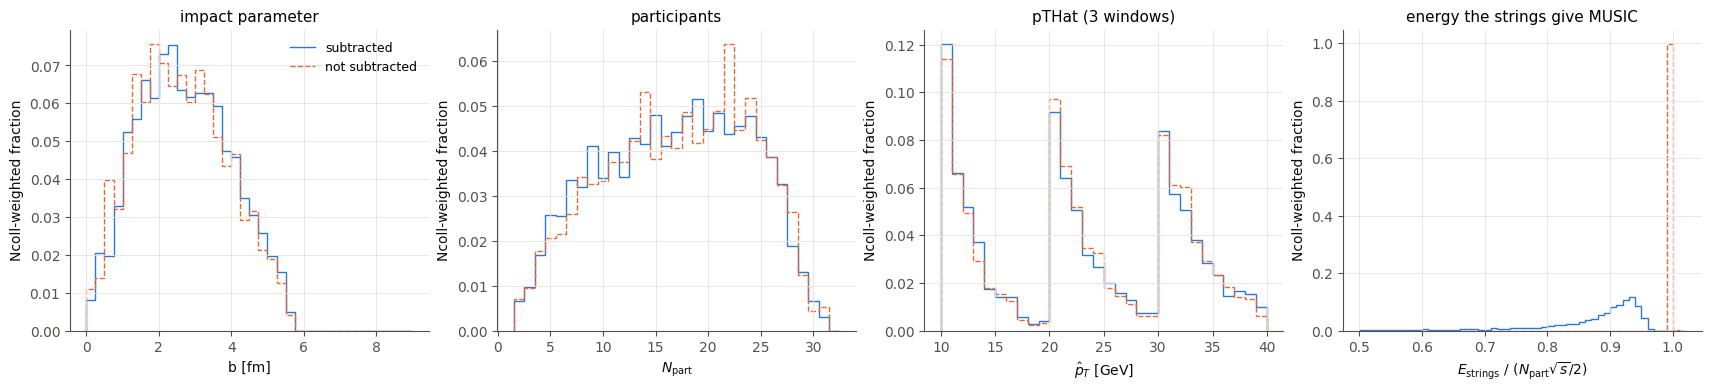

In [4]:
def step(ax, values, bins, weights=None, density=False, norm=1.0, **style):
    n, edges = np.histogram(values, bins=bins, weights=weights)
    n = n / norm
    if density:
        n = n / np.diff(edges)
    ax.stairs(n, edges, **style)
    return n, edges

fig, ax = plt.subplots(1, 4, figsize=(17, 3.8), constrained_layout=True)
for name, c in C.items():
    e, st = c["events"], STYLE[name]
    wn = e["wt"] / e["wt"].sum()
    step(ax[0], e["glauber_b"], np.linspace(0, 9, 37), weights=wn, **st)
    step(ax[1], e["glauber_npart"], np.arange(1.5, 33.5, 1), weights=wn, **st)
    step(ax[2], e["pthat"], np.arange(10, 40.5, 1), weights=wn, **st)
    step(ax[3], e["strings_E_total"] / e["E_beam"], np.linspace(0.5, 1.02, 53), weights=wn, **st)
wl = "Ncoll-weighted fraction" if WEIGHT == "ncoll" else "fraction of events"
ax[0].set(xlabel="b [fm]", ylabel=wl, title="impact parameter")
ax[1].set(xlabel="$N_\\mathrm{part}$", ylabel=wl, title="participants")
ax[2].set(xlabel="$\\hat p_T$ [GeV]", ylabel=wl, title="pTHat (3 windows)")
ax[3].set(xlabel="$E_\\mathrm{strings}$ / ($N_\\mathrm{part}\\sqrt{s}/2$)", ylabel=wl,
          title="energy the strings give MUSIC")
ax[0].legend()
plt.show()

## 2. The centrality bias

Centrality is measured from the multiplicity, not from b. The subtraction takes the hard
pair's energy out of the strings, so an event with a hard scattering makes a smaller bulk
than its geometry would, and is classified more peripheral. The hard pair's energy is a
fixed amount, so the relative loss, and with it the bias, grows towards small Npart.

**(a)** What the hard pair takes, relative to the participants' energy, and **(b)** the
charged multiplicity in the estimator window (bulk, mean over the samples, plus the jet
hadrons), both against Npart; **(c)** the ratio of (b), subtracted / not subtracted.

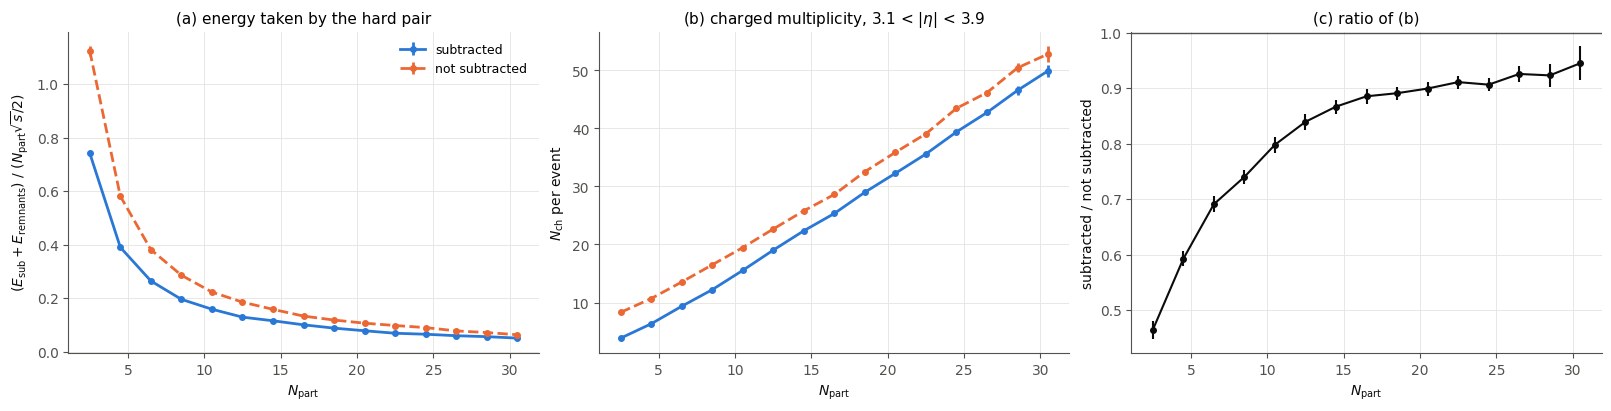

In [5]:
NP_BINS = np.arange(1.5, 33.5, 2)
EST_LABEL = (f"{ETA_EST[0]:g} < |$\\eta$| < {ETA_EST[1]:g}" if ETA_EST[0] > 0
             else f"|$\\eta$| < {ETA_EST[1]:g}")
fig, ax = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True, sharex=True)
prof = {}
for name, c in C.items():
    e, st = c["events"], STYLE[name]
    for k, y in enumerate((e["hard_E"] / e["E_beam"], e["bulk_est_mean"] + e["jet_est"])):
        xc, m, err = profile(e["glauber_npart"], y, e["wt"], NP_BINS)
        ax[k].errorbar(xc, m, yerr=err, marker="o", ms=4, **st)
        if k == 1:
            prof[name] = (m, err)
(ma, ea), (mb, eb) = prof["sub"], prof["nosub"]
r = ma / mb
ax[2].errorbar(xc, r, yerr=r * np.hypot(ea / ma, eb / mb), marker="o", ms=4, color=C_INK, lw=1.5)
ax[2].axhline(1, color=C_MUTED, lw=1)
ax[0].set(ylabel="($E_\\mathrm{sub} + E_\\mathrm{remnants}$) / ($N_\\mathrm{part}\\sqrt{s}/2$)",
          title="(a) energy taken by the hard pair")
ax[1].set(ylabel="$N_\\mathrm{ch}$ per event", title=f"(b) charged multiplicity, {EST_LABEL}")
ax[2].set(ylabel="subtracted / not subtracted", title="(c) ratio of (b)")
for a_ in ax:
    a_.set_xlabel("$N_\\mathrm{part}$")
ax[0].legend()
plt.show()

**Centrality classes.** The class boundaries come from a multiplicity distribution
**without** a hard scattering's effect: the not-subtracted bulk alone (one sample,
unweighted: every collision of the b range once), whose strings carry the full
Npart √s/2. The b range covers 0–`CENT_MAX` % of the inelastic cross section, so a class
c % is the fraction c / `CENT_MAX` of this sample (approximately: a multiplicity class is
not a b class, so events beyond the b cut that would land in 60–80% are missing). Each campaign's events are then classified by what an experiment would count,
bulk (one sample) plus jet hadrons. Three classifications of hard events (all weighted
with `WEIGHT`):

- **reference**, ink dotted: the not-subtracted events by their bulk alone, i.e. as their
  geometry would place them without any hard-scattering effect,
- **not subtracted**: bulk + jet hadrons (the jet's own multiplicity in the window),
- **subtracted**: bulk + jet hadrons, with the bulk reduced by the subtraction.

The difference between subtracted and not subtracted is the bias the subtraction adds; the
difference to the reference is the whole bias of the hard event. Integer counts are
smeared with a uniform random number in [0, 1) so that ties do not shift the boundaries.

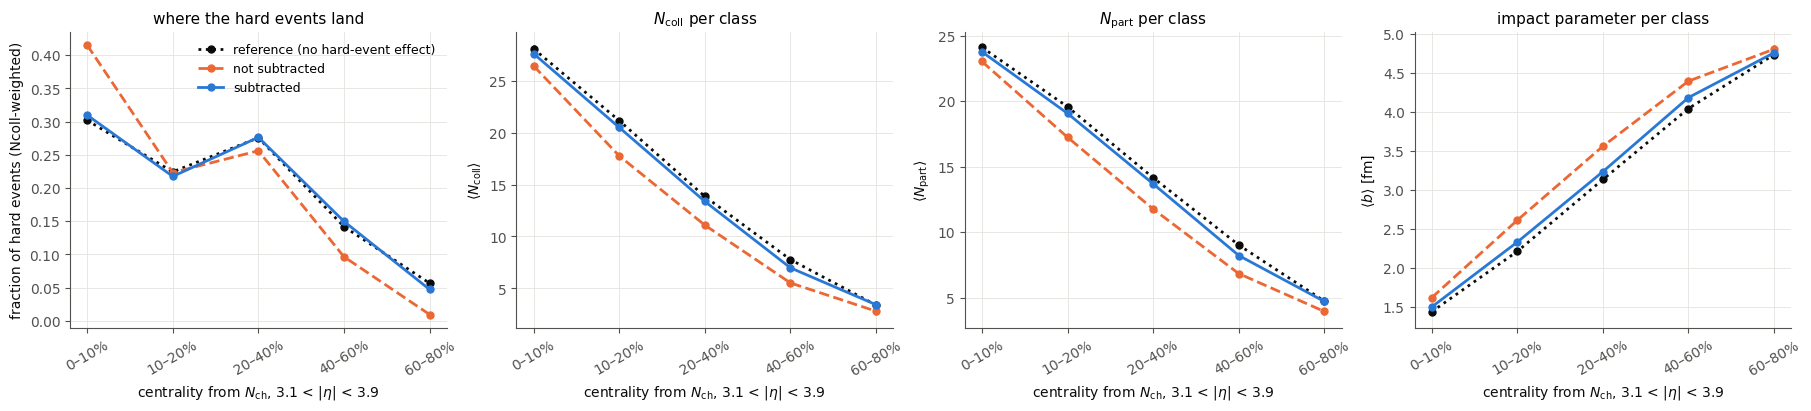

class boundaries (charged hadrons, 3.1 < |eta| < 3.9, one sample): 34.1, 25.3, 14.0, 6.3

    class                  reference             not subtracted                 subtracted
    0–10%   Ncoll  28.07 ± 0.35 (30.2%)   Ncoll  26.42 ± 0.31 (41.5%)   Ncoll  27.60 ± 0.35 (31.0%)
   10–20%   Ncoll  21.15 ± 0.29 (22.4%)   Ncoll  17.75 ± 0.30 (22.3%)   Ncoll  20.49 ± 0.33 (21.7%)
   20–40%   Ncoll  13.85 ± 0.22 (27.6%)   Ncoll  11.09 ± 0.19 (25.6%)   Ncoll  13.37 ± 0.21 (27.6%)
   40–60%   Ncoll   7.77 ± 0.19 (14.2%)   Ncoll   5.52 ± 0.18 ( 9.6%)   Ncoll   6.98 ± 0.15 (15.0%)
   60–80%   Ncoll   3.39 ± 0.10 ( 5.7%)   Ncoll   2.80 ± 0.32 ( 0.9%)   Ncoll   3.42 ± 0.10 ( 4.7%)


In [6]:
rng = np.random.default_rng(12345)
ref = C["nosub"]["events"]
x_ref = ref["bulk_est"] + rng.random(C["nosub"]["n"])          # minimum-bias soft estimator
# class k: CENT_EDGES[k]-CENT_EDGES[k+1] % most central = the highest multiplicities
q = np.quantile(x_ref, 1 - np.asarray(CENT_EDGES) / CENT_MAX)  # descending thresholds
q[0], q[-1] = np.inf, -np.inf

def classify(x):
    return np.searchsorted(-q, -x, side="right") - 1           # 0 = most central

CLASSIFIED = {
    "reference": (ref, classify(x_ref)),
    "nosub": (ref, classify(ref["est"] + rng.random(C["nosub"]["n"]))),
    "sub": (C["sub"]["events"], classify(C["sub"]["events"]["est"] + rng.random(C["sub"]["n"]))),
}
REF_STYLE = dict(color=C_INK, ls=":", label="reference (no hard-event effect)")
labels = [f"{lo}–{hi}%" for lo, hi in zip(CENT_EDGES[:-1], CENT_EDGES[1:])]
nk = len(labels)
xk = np.arange(nk)

rows = {}
for case, (e, cls) in CLASSIFIED.items():
    w = e["wt"]
    frac = np.array([w[cls == k].sum() for k in range(nk)]) / w.sum()
    stats = {}
    for key in ("glauber_ncoll", "glauber_npart", "glauber_b"):
        stats[key] = np.array([wmean(e[key][cls == k], w[cls == k]) for k in range(nk)])
    rows[case] = dict(frac=frac, n=np.bincount(cls, minlength=nk), **stats)

fig, ax = plt.subplots(1, 4, figsize=(18, 4), constrained_layout=True, sharex=True)
for case in ("reference", "nosub", "sub"):
    st = REF_STYLE if case == "reference" else STYLE[case]
    r_ = rows[case]
    ax[0].plot(xk, r_["frac"], marker="o", ms=5, **st)
    for j, key in enumerate(("glauber_ncoll", "glauber_npart", "glauber_b")):
        m, err = r_[key][:, 0], r_[key][:, 1]
        ax[j + 1].errorbar(xk, m, yerr=err, marker="o", ms=5, **st)
ax[0].set(ylabel="fraction of hard events" + (" (Ncoll-weighted)" if WEIGHT == "ncoll" else ""),
          title="where the hard events land")
ax[1].set(ylabel="$\\langle N_\\mathrm{coll}\\rangle$", title="$N_\\mathrm{coll}$ per class")
ax[2].set(ylabel="$\\langle N_\\mathrm{part}\\rangle$", title="$N_\\mathrm{part}$ per class")
ax[3].set(ylabel="$\\langle b\\rangle$ [fm]", title="impact parameter per class")
for a_ in ax:
    a_.set_xticks(xk, labels, rotation=30)
    a_.set_xlabel(f"centrality from $N_\\mathrm{{ch}}$, {EST_LABEL}")
ax[0].legend()
plt.show()

print(f"class boundaries (charged hadrons, {ETA_EST[0]:g} < |eta| < {ETA_EST[1]:g}, one sample): "
      + ", ".join(f"{v:.1f}" for v in q[1:-1]))
print(f"\n{'class':>9s}" + "".join(f"{c:>27s}" for c in ("reference", "not subtracted", "subtracted")))
for k in range(nk):
    line = f"{labels[k]:>9s}"
    for case in ("reference", "nosub", "sub"):
        m, err = rows[case]["glauber_ncoll"][k]
        line += f"   Ncoll {m:6.2f} ± {err:4.2f} ({100 * rows[case]['frac'][k]:4.1f}%)"
    print(line)

## 3. The bulk

iSS hadrons on MUSIC's freeze-out surface, per event and sample, weighted with `WEIGHT`.
The ratio panels are subtracted / not subtracted; the band is the statistical error of the
ratio (events as the independent unit). dE/dη shows where the energy taken from the
strings is missing.

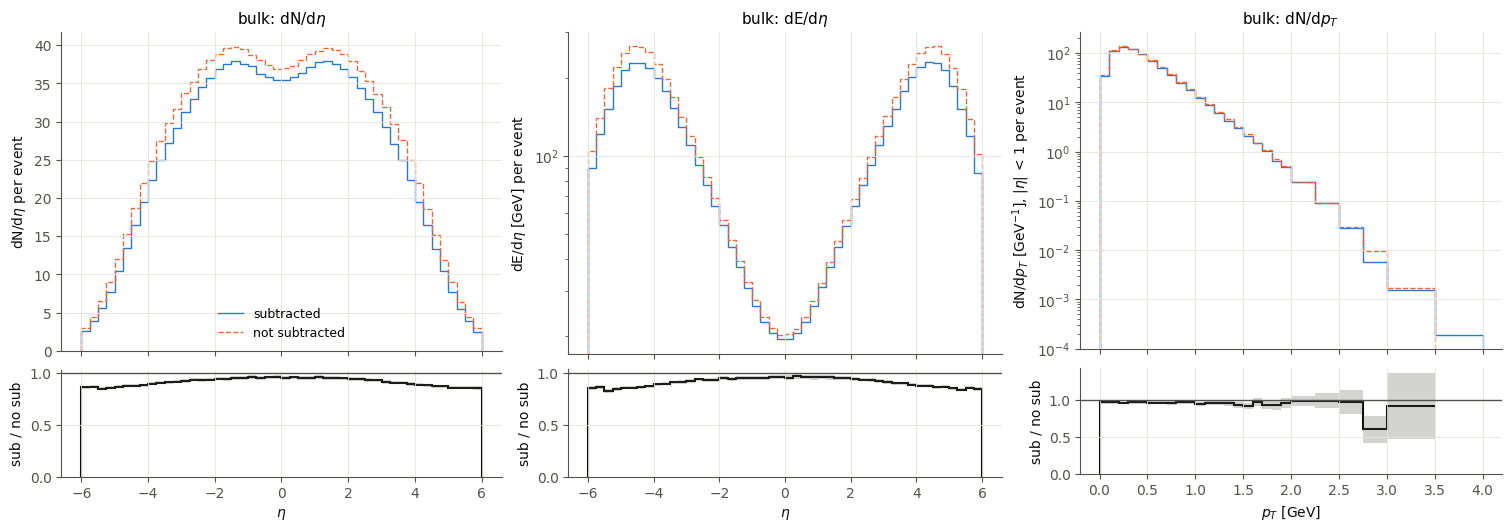

In [7]:
ETA_BINS = np.linspace(-6, 6, 49)
PT_BINS = np.concatenate([np.arange(0, 2, 0.1), np.arange(2, 3, 0.25), [3, 3.5, 4]])

def spectrum(c, tag, x, bins, mask=None, value=None, events=None):
    # weighted per-event mean of a differential distribution and its error
    h = c["hadrons"][tag]
    sel = np.ones(len(h["E"]), bool) if mask is None else mask(h)
    w = h["w"][sel].astype(np.float64) * (1.0 if value is None else value(h)[sel])
    xb = np.digitize(x(h)[sel], bins) - 1
    ok = (xb >= 0) & (xb < len(bins) - 1)
    flat = h["unit"][sel][ok] * (len(bins) - 1) + xb[ok]
    s = np.bincount(flat, weights=w[ok], minlength=c["n"] * (len(bins) - 1))
    s = s.reshape(c["n"], len(bins) - 1)
    wt = c["events"]["wt"]
    if events is not None:
        s, wt = s[events], wt[events]
    m = (wt[:, None] * s).sum(0) / wt.sum()
    err = np.sqrt((wt[:, None] ** 2 * (s - m) ** 2).sum(0)) / wt.sum()
    return m / np.diff(bins), err / np.diff(bins)

def ratio(out):
    (ma, ea), (mb, eb) = out["sub"], out["nosub"]
    with np.errstate(divide="ignore", invalid="ignore"):
        r = ma / mb
        return r, r * np.sqrt((ea / ma) ** 2 + (eb / mb) ** 2)

def compare(ax_top, ax_rat, tag, x, bins, mask=None, value=None, log=False):
    out = {}
    for name, c in C.items():
        out[name] = spectrum(c, tag, x, bins, mask=mask, value=value)
        ax_top.stairs(out[name][0], bins, **STYLE[name])
    r, er = ratio(out)
    ax_rat.stairs(r, bins, color=C_INK, lw=1.5)
    ax_rat.stairs(r + er, bins, baseline=r - er, fill=True, color=C_MUTED, alpha=0.25, lw=0)
    ax_rat.axhline(1, color=C_MUTED, lw=1)
    ax_rat.set_ylabel("sub / no sub")
    if log:
        ax_top.set_yscale("log")

eta = lambda h: h["eta"]
pt = lambda h: h["pt"]
energy = lambda h: h["E"]
mid_pt = lambda h: np.abs(h["eta"]) < ETA_PT

def spectra_figure(tag, title, pt_bins):
    fig = plt.figure(figsize=(15, 5.2), constrained_layout=True)
    outer = fig.add_gridspec(1, 3)
    specs = [("dN/d$\\eta$", "$\\eta$", dict(x=eta, bins=ETA_BINS), False),
             ("dE/d$\\eta$ [GeV]", "$\\eta$", dict(x=eta, bins=ETA_BINS, value=energy), True),
             (f"dN/d$p_T$ [GeV$^{{-1}}$], |$\\eta$| < {ETA_PT:g}", "$p_T$ [GeV]",
              dict(x=pt, bins=pt_bins, mask=mid_pt), True)]
    for k, (ylab, xlab, kw, log) in enumerate(specs):
        gs = outer[k].subgridspec(2, 1, height_ratios=(3, 1))
        top = fig.add_subplot(gs[0])
        rat = fig.add_subplot(gs[1], sharex=top)
        compare(top, rat, tag, log=log, **kw)
        top.set(ylabel=ylab + " per event", title=f"{title}: " + ylab.split(" [")[0].split(",")[0])
        rat.set(xlabel=xlab)
        plt.setp(top.get_xticklabels(), visible=False)
        if k == 0:
            top.legend()
    plt.show()

spectra_figure("bulk", "bulk", PT_BINS)

**Per pTHat window.** The energy the hard pair takes grows with pTHat, so the bulk's
difference may grow with it. Ratio of dN/dη and dE/dη, subtracted / not subtracted:

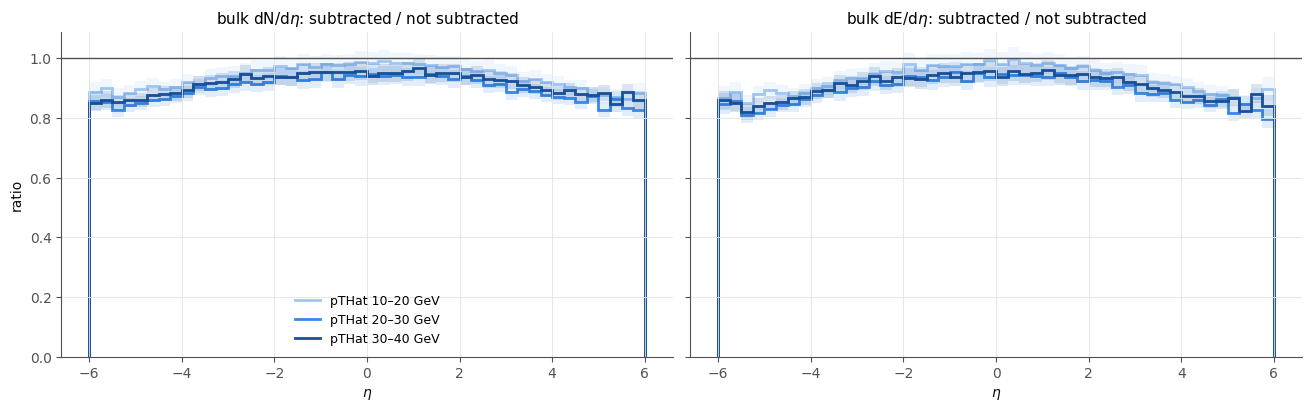

In [8]:
WINDOWS = ["10–20 GeV", "20–30 GeV", "30–40 GeV"]
win_style = [dict(color=c, lw=2) for c in ("#9ec5f4", "#3987e5", "#184f95")]  # ordinal ramp
fig, ax = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True, sharey=True)
for j, (value, title) in enumerate(((None, "dN/d$\\eta$"), (energy, "dE/d$\\eta$"))):
    for w in range(3):
        out = {name: spectrum(c, "bulk", eta, ETA_BINS, value=value,
                              events=c["events"]["pthat_bin"] == w) for name, c in C.items()}
        r, er = ratio(out)
        ax[j].stairs(r, ETA_BINS, label=f"pTHat {WINDOWS[w]}", **win_style[w])
        ax[j].stairs(r + er, ETA_BINS, baseline=r - er, fill=True, alpha=0.15,
                     color=win_style[w]["color"], lw=0)
    ax[j].axhline(1, color=C_MUTED, lw=1)
    ax[j].set(xlabel="$\\eta$", title=f"bulk {title}: subtracted / not subtracted")
ax[0].set_ylabel("ratio")
ax[0].legend()
plt.show()

## 4. The jet hadrons

iColored hadronization of the hard nucleon pair: the dijet (Matter in the medium), the ISR
emissions, Pythia's MPI partons and the pair's beam remnants, one sample per event. The
subtraction acts on them through the remnants (3dMCGlauber gives the hard pair's remnants
other momenta with and without it: compare `E_remnants` in section 6) and through the medium
Matter sees.

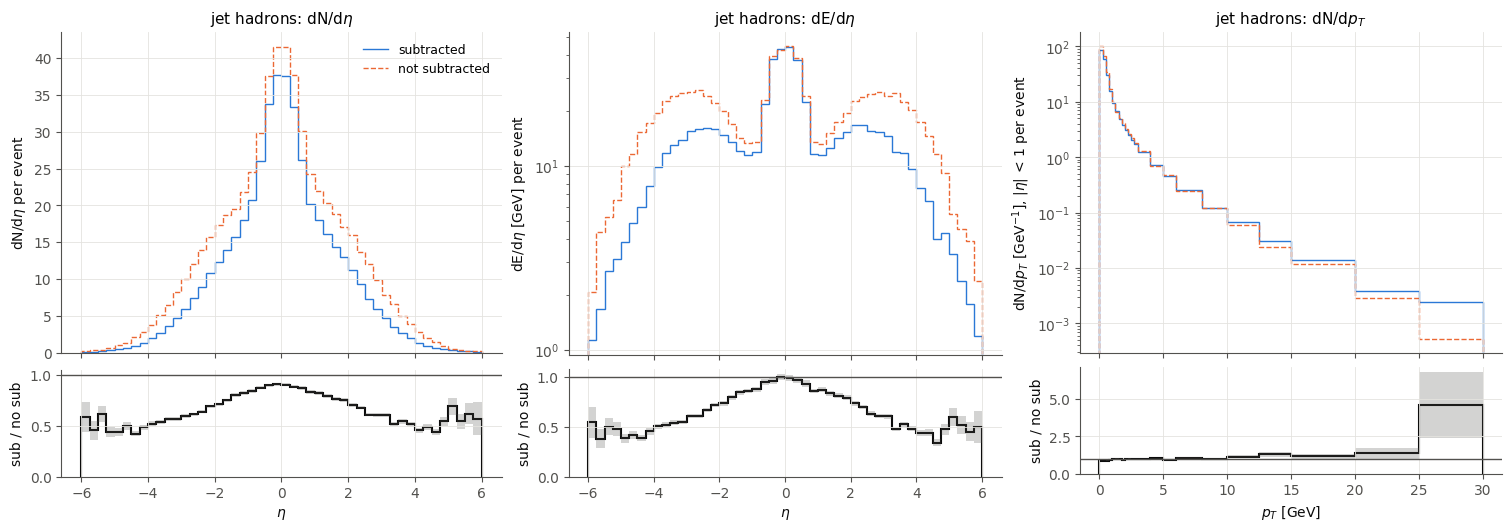

In [9]:
JET_PT_BINS = np.concatenate([np.arange(0, 3, 0.25), [3, 4, 5, 6, 8, 10, 12.5, 15, 20, 25, 30]])
spectra_figure("jet", "jet hadrons", JET_PT_BINS)

## 5. The energy as a function of the parton pT

Per event, binned in the hard partons' pT (`PT_VAR`, default pTHat), weighted mean ±
standard error. The energies are divided by the participants' beam energy, Npart √s/2,
which takes out the geometry:

- **(a)** the hard pair's share as 3dMCGlauber records it, E_sub + E_remnants (with the
  subtraction: taken from the strings; without it: given to the jet hadronization on top),
- **(b)** the bulk hadrons' energy (all η),
- **(c)** the jet hadrons' energy (all η),
- **(d)** all hadrons; energy conservation of the whole event would put this at 1 (line).

Below, the bulk's energy, transverse energy and multiplicity at midrapidity, where the
hard partons (|y| < 0.6) sit.

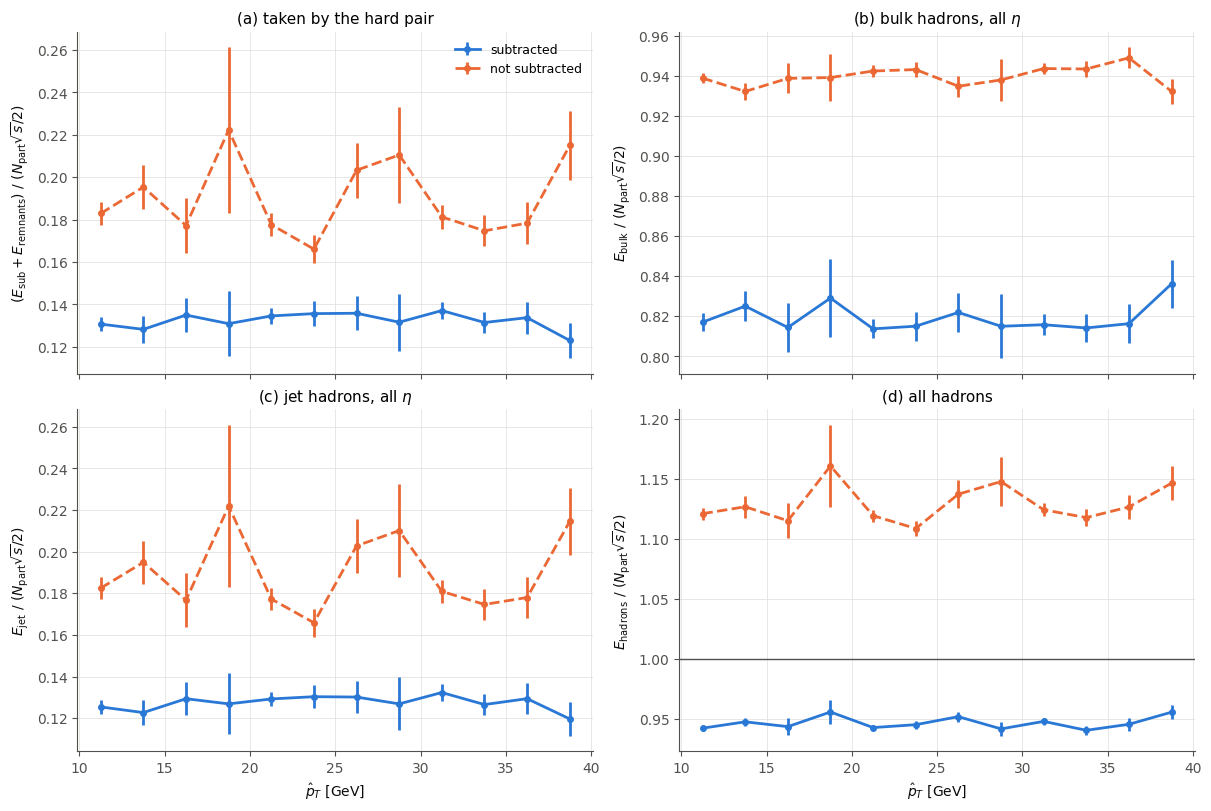

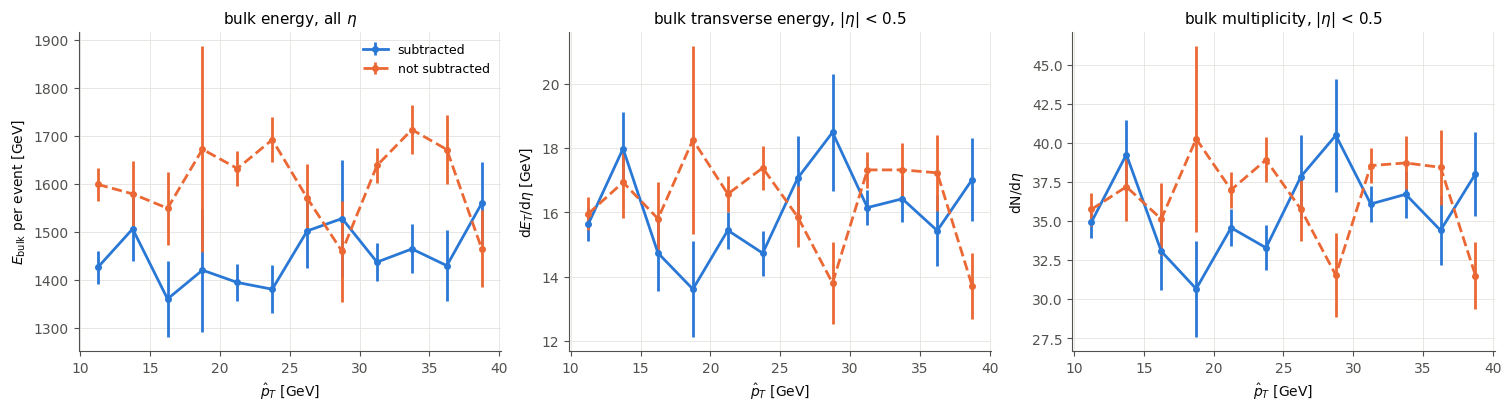

In [10]:
X_BINS = np.arange(10, 42.5, 2.5)
XLAB = {"pthat": "$\\hat p_T$ [GeV]",
        "parton_pt_lead": "harder hard parton's $p_T$ after ISR [GeV]"}[PT_VAR]

def plot_profile(ax, name, y):
    e = C[name]["events"]
    xc, m, err = profile(e[PT_VAR], y(e), e["wt"], X_BINS)
    ax.errorbar(xc, m, yerr=err, marker="o", ms=4, **STYLE[name])

fig, ax = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True, sharex=True)
rel = lambda key: (lambda e: e[key] / e["E_beam"])
for name in C:
    plot_profile(ax[0, 0], name, rel("hard_E"))
    plot_profile(ax[0, 1], name, rel("bulk_E"))
    plot_profile(ax[1, 0], name, rel("jet_E"))
    plot_profile(ax[1, 1], name, rel("hadrons_E"))
ax[0, 0].set(ylabel="($E_\\mathrm{sub} + E_\\mathrm{remnants}$) / ($N_\\mathrm{part}\\sqrt{s}/2$)",
             title="(a) taken by the hard pair")
ax[0, 1].set(ylabel="$E_\\mathrm{bulk}$ / ($N_\\mathrm{part}\\sqrt{s}/2$)",
             title="(b) bulk hadrons, all $\\eta$")
ax[1, 0].set(ylabel="$E_\\mathrm{jet}$ / ($N_\\mathrm{part}\\sqrt{s}/2$)",
             title="(c) jet hadrons, all $\\eta$")
ax[1, 1].set(ylabel="$E_\\mathrm{hadrons}$ / ($N_\\mathrm{part}\\sqrt{s}/2$)",
             title="(d) all hadrons")
ax[1, 1].axhline(1, color=C_MUTED, lw=1)
for a_ in ax[1]:
    a_.set_xlabel(XLAB)
ax[0, 0].legend()
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True, sharex=True)
for name in C:
    plot_profile(ax[0], name, lambda e: e["bulk_E"])
    plot_profile(ax[1], name, lambda e: e["bulk_dETdeta_mid"])
    plot_profile(ax[2], name, lambda e: e["bulk_dNdeta_mid"])
ax[0].set(ylabel="$E_\\mathrm{bulk}$ per event [GeV]", title="bulk energy, all $\\eta$")
ax[1].set(ylabel="d$E_T$/d$\\eta$ [GeV]", title=f"bulk transverse energy, |$\\eta$| < {MID:g}")
ax[2].set(ylabel="dN/d$\\eta$", title=f"bulk multiplicity, |$\\eta$| < {MID:g}")
for a_ in ax:
    a_.set_xlabel(XLAB)
ax[0].legend()
plt.show()

## 6. Summary per pTHat window

Weighted means over the events of each window (± standard error). Δ is subtracted − not
subtracted, relative to not subtracted; the error of Δ adds the two in quadrature.

In [11]:
QUANT = [("glauber_npart", "Npart"),
         ("glauber_ncoll", "Ncoll"),
         ("glauber_b", "b [fm]"),
         ("isr_sub_E_total", "E_sub [GeV]"),
         ("remnant_E", "E_remnants [GeV]"),
         ("strings_E_total", "E_strings [GeV]"),
         ("bulk_E", "E_bulk [GeV]"),
         ("jet_E", "E_jet [GeV]"),
         ("hadrons_E", "E_hadrons [GeV]"),
         ("bulk_dNdeta_mid", f"bulk dN/deta |eta|<{MID:g}"),
         ("bulk_dETdeta_mid", f"bulk dET/deta |eta|<{MID:g} [GeV]"),
         ("jet_dNdeta_mid", f"jet dN/deta |eta|<{MID:g}"),
         ("est", f"N_ch {ETA_EST[0]:g}<|eta|<{ETA_EST[1]:g} (estimator)")]

lines = []
for w in range(3):
    lines.append(f"\npTHat {WINDOWS[w]}  "
                 + "  ".join(f"{CAMPAIGNS[n]}: {int((C[n]['events']['pthat_bin'] == w).sum())} events"
                             for n in C))
    lines.append(f"{'':40s}{'subtracted':>20s}{'not subtracted':>20s}{'delta':>16s}")
    for key, label in QUANT:
        (ma, ea), (mb, eb) = (wmean(C[n]["events"][key][C[n]["events"]["pthat_bin"] == w],
                                    C[n]["events"]["wt"][C[n]["events"]["pthat_bin"] == w])
                              for n in ("sub", "nosub"))
        d = (ma - mb) / mb if mb else np.nan
        de = np.hypot(ea, eb) / abs(mb) if mb else np.nan
        lines.append(f"{label:40s}{ma:12.2f} ± {ea:5.2f}{mb:12.2f} ± {eb:5.2f}"
                     f"{100 * d:+9.1f} ± {100 * de:3.1f}%")
print("\n".join(lines))


pTHat 10–20 GeV  subtracted: 997 events  not subtracted: 999 events
                                                  subtracted      not subtracted           delta
Npart                                          16.76 ±  0.29       16.81 ±  0.29     -0.3 ± 2.4%
Ncoll                                          17.85 ±  0.43       17.99 ±  0.45     -0.8 ± 3.5%
b [fm]                                          2.70 ±  0.05        2.66 ±  0.05     +1.3 ± 2.8%
E_sub [GeV]                                   103.93 ±  1.13      104.16 ±  1.22     -0.2 ± 1.6%
E_remnants [GeV]                               56.15 ±  1.14      115.49 ±  1.90    -51.4 ± 1.9%
E_strings [GeV]                              1522.97 ± 28.74     1681.00 ± 29.28     -9.4 ± 2.4%
E_bulk [GeV]                                 1438.03 ± 28.44     1592.35 ± 28.94     -9.7 ± 2.5%
E_jet [GeV]                                   153.50 ±  1.11      219.11 ±  2.29    -29.9 ± 1.2%
E_hadrons [GeV]                              1591.53 ± 28.

In [12]:
# the cross section of the |y| < 0.6 selection per window (Pythia's x the acceptance), from
# the jobs' summaries: the same Pythia streams, so the same numbers in both campaigns
for name, c in C.items():
    acc = np.array([j["pthat_bin_acceptance"] for j in c["jobs"] if "pthat_bin_acceptance" in j])
    sig = np.array([j["pthat_bin_sigma_gen"] for j in c["jobs"]])
    if len(acc):
        print(f"{CAMPAIGNS[name]:15s}: acceptance |y|<0.6 per window "
              + ", ".join(f"{a:.3f}" for a in acc.mean(0))
              + "; sigma [mb] " + ", ".join(f"{s:.3g}" for s in sig.mean(0)))

subtracted     : acceptance |y|<0.6 per window 0.139, 0.304, 0.491; sigma [mb] 0.000788, 2.3e-05, 1.44e-06
not subtracted : acceptance |y|<0.6 per window 0.139, 0.304, 0.491; sigma [mb] 0.000788, 2.3e-05, 1.44e-06
